# 🌱 Lesson 1: Data Cleaning I: Types, Duplicates & Missing Values
**Phase 2 · Data Preprocessing & Feature Engineering** &nbsp;|&nbsp; ⏱ about 2–3 hours &nbsp;|&nbsp; 📚 Prerequisite: Lesson 00

> *The most expensive bug is the one that never raises an error.*

## 🎯 By the end of this lesson you will be able to
- Inspect a dataset systematically and recognise common quality problems.
- Convert messy text into proper numeric, datetime and categorical types.
- Find exact, near and key-based duplicates and remove them safely.
- Diagnose *why* values are missing (MCAR, MAR, MNAR) and choose a strategy.
- Apply mean, median, group-wise and indicator-based imputation, and know their side-effects.

---

## 🧼 Why cleaning comes first

Suppose a crop-yield model sees a farm with `soil_ph = 99`. The model has no idea pH is limited to 0–14. It will simply **believe** that number and bend its predictions around it.
Models are very obedient students: they learn exactly what you teach, including your typos.

> **Analogy:** You wouldn't use a ruler that has a bit snapped off and the numbers painted wrong. Cleaning is checking that the ruler is correct *before* measuring anything with it.

### 🧭 An important design decision: two kinds of cleaning

| | **Structural cleaning** | **Statistical cleaning** |
|---|---|---|
| Examples | Fix types, remove duplicates, standardise spelling, mark impossible values as NaN | Fill missing values, cap outliers, scale |
| Learns numbers from the data? | ❌ No: rule based (`pH must be 0–14`) | ✅ Yes: mean, median, quartiles… |
| When? | Once, up-front, on the whole dataset | **Inside a pipeline, fitted on the training set only** |

Why the split? Because anything that *learns a number from the data* (a mean, a median, a cap) must learn it from the training data alone. Otherwise the test set secretly influences training: **data leakage** (Lesson 6).

In Lessons 1–2 we do structural cleaning for real. We will *demonstrate* statistical techniques (imputation) on the full dataset so you can see the mechanics, but in Lesson 7 we'll redo them the safe way, inside a pipeline.

In [1]:
import sys
sys.path.append("../utils")            # lets us import course_utils.py and agri_prep.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from course_utils import *             # load_raw_farm, profile, setup_plots, ...

setup_plots()
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 140)
np.random.seed(42)

In [2]:
raw = load_raw_farm()
df = raw.copy()          # our working copy. raw stays untouched.
df.shape

(2485, 22)

---
# Part 1 · Data type conversion

## 1.1 Why types matter
A column's *dtype* decides what you are allowed to do with it. You cannot average text. You cannot ask "which date is later?" of a string. Here's what the raw file gave us:

In [3]:
df.dtypes.to_frame("dtype").T

,farm_id,county,soil_type,farm_size_ha,experience,crop,season,planting_date,harvest_date,rainfall_mm,avg_temp_c,soil_ph,nitrogen_ppm,phosphorus_ppm,potassium_ppm,organic_matter_pct,fertilizer_kg_ha,irrigation,pest_pressure,market_price_ksh_kg,total_revenue_ksh,yield_t_ha
dtype,str,str,str,float64,str,str,str,str,str,float64,float64,float64,float64,float64,float64,float64,str,str,str,float64,float64,float64


### Worked example: a tiny dataset first
Let's see the conversion mechanics on four rows where every value is visible. (Always prototype on a toy example; bugs are easy to spot when the data is tiny.)

In [4]:
toy = pd.DataFrame({
    "farm":    ["A", "B", "C", "D"],
    "fert":    ["85", "120 kg", "N/A", "60kg/ha"],
    "planted": ["2023-03-14", "14 Mar 2023", "2023-04-02", "2023/04/10"],
})
toy

,farm,fert,planted
0,A,85,2023-03-14
1,B,120 kg,14 Mar 2023
2,C,N/A,2023-04-02
3,D,60kg/ha,2023/04/10


**Attempt 1: the naive way.** What do you think happens?

In [5]:
try:
    pd.to_numeric(toy["fert"])
except Exception as e:
    print("❌ Error:", e)

❌ Error: Unable to parse string "120 kg" at position 1


Python refuses, loudly. That is *good*: it told us there's a problem. The tempting shortcut is `errors='coerce'`, which silently turns every failure into NaN:

In [6]:
pd.to_numeric(toy["fert"], errors="coerce")

0    85.0
1     NaN
2     NaN
3     NaN
Name: fert, dtype: float64

`'120 kg'` and `'60kg/ha'` became NaN even though they **contain perfectly good numbers**. We lost data and nothing warned us. This is the danger of `coerce`.

**Attempt 2: extract the number with a regular expression:**

In [7]:
pattern = r"(\d+\.?\d*)"        # one or more digits, optionally followed by a decimal part
extracted = toy["fert"].str.extract(pattern, expand=False)
print(extracted.tolist())
toy["fert_num"] = pd.to_numeric(extracted)
toy

['85', '120', nan, '60']


,farm,fert,planted,fert_num
0,A,85,2023-03-14,85.0
1,B,120 kg,14 Mar 2023,120.0
2,C,N/A,2023-04-02,NaN
3,D,60kg/ha,2023/04/10,60.0


Reading the pattern `(\d+\.?\d*)`: `\d+` = one or more digits · `\.?` = an optional dot · `\d*` = more digits · the parentheses *capture* that part.
Now 85, 120 and 60 are rescued and only `'N/A'` (genuinely no number) becomes NaN. 

**Dates** have the same story. `format="mixed"` tells pandas to figure out each string separately:

In [8]:
toy["planted_dt"] = pd.to_datetime(toy["planted"], format="mixed")
toy[["planted", "planted_dt"]]

,planted,planted_dt
0,2023-03-14,2023-03-14
1,14 Mar 2023,2023-03-14
2,2023-04-02,2023-04-02
3,2023/04/10,2023-04-10


> ⚠️ **Date format traps.** `04/05/2023` is April 5th in the US and 4 May in Kenya/UK. With ambiguous strings, never guess: find out the convention (or use `dayfirst=True/False`). Our dataset only mixes *unambiguous* formats (`2023-03-14` and `14 Mar 2023`).

### Now the real thing: fertilizer

In [9]:
fert_text = df["fertilizer_kg_ha"]
print("Sample of raw strings:", fert_text.dropna().sample(8, random_state=1).tolist())

# What are the values that contain NO digits at all?
no_digit = fert_text.dropna()[~fert_text.dropna().str.contains(r"\d")]
print("Pure placeholders:", list(no_digit.unique()))
print("(Note: 'N/A' strings were already turned into NaN by read_csv when the file was loaded.)")

Sample of raw strings: ['114', '62', '53', '129', '125 kg', '0', '62', '65 kg']
Pure placeholders: ['-', 'unknown']
(Note: 'N/A' strings were already turned into NaN by read_csv when the file was loaded.)


In [10]:
before = df["fertilizer_kg_ha"].isna().sum()
df["fertilizer_kg_ha"] = pd.to_numeric(df["fertilizer_kg_ha"].str.extract(r"(\d+\.?\d*)", expand=False))
after = df["fertilizer_kg_ha"].isna().sum()
print(f"Missing before: {before} | after: {after} | newly missing = placeholders: {after - before}")
df["fertilizer_kg_ha"].describe().round(1)

Missing before: 260 | after: 341 | newly missing = placeholders: 81


count    2144.0
mean       76.0
std       145.3
min         0.0
25%        33.0
50%        70.0
75%       101.0
max      2955.0
Name: fertilizer_kg_ha, dtype: float64

Check the maximum above: some farms apparently use ~2,000+ kg/ha: a hundred times typical. That's an **outlier** we will deal with in Lesson 2. (Good cleaners keep a notebook of *suspicions* as they go.)

### Dates

In [11]:
for col in ["planting_date", "harvest_date"]:
    df[col] = pd.to_datetime(df[col], format="mixed")

print(df[["planting_date", "harvest_date"]].dtypes.to_dict())
print("Planting range:", df["planting_date"].min().date(), "→", df["planting_date"].max().date())
print("Harvest range :", df["harvest_date"].min().date(), "→", df["harvest_date"].max().date())

{'planting_date': dtype('<M8[us]'), 'harvest_date': dtype('<M8[us]')}
Planting range: 2019-03-01 → 2023-11-27
Harvest range : 2018-01-15 → 2024-05-11


A harvest date in **2018** when planting only starts in 2019? Another thing to investigate in Lesson 2. Types fixed ✅: now we can do date arithmetic.

## 1.2 The `category` dtype
Columns with a small number of repeated labels (crop, soil type) can be stored as `category`. It saves memory and signals *"this is a label, not free text"*.
Compare:

In [12]:
mem_obj = df["soil_type"].astype("object").memory_usage(deep=True)
mem_cat = df["soil_type"].astype("category").memory_usage(deep=True)
print(f"as text: {mem_obj:,} bytes | as category: {mem_cat:,} bytes  ({mem_cat / mem_obj:.0%} of the size)")

as text: 132,840 bytes | as category: 3,481 bytes  (3% of the size)


We'll convert categories after we've fixed their spellings (Lesson 2): converting before would just create categories for each typo. **Order of operations matters.**

---
# Part 2 · Duplicate removal

## 2.1 Why duplicates hurt
Duplicates **over-weight** some observations: the model sees the same farm twice and thinks that pattern is twice as common. Worse, if a duplicate lands in the test set while its twin is in the training set, you're testing the model on data it has already memorised: **leakage** again.

## 2.2 The mechanics on a toy table

In [13]:
t = pd.DataFrame({
    "farm_id": ["F1", "F2", "F2", "F3", "F3"],
    "crop":    ["Maize", "Beans", "Beans", "Maize", "MAIZE"],
    "yield":   [3.1, 1.2, 1.2, 2.8, 2.8],
})
print("duplicated() flags the 2nd+ copy:\n", t.duplicated().tolist())
print("keep=False flags ALL copies    :", t.duplicated(keep=False).tolist())
print("by farm_id + yield only        :", t.duplicated(subset=["farm_id", "yield"]).tolist())

duplicated() flags the 2nd+ copy:
 [False, False, True, False, False]
keep=False flags ALL copies    : [False, True, True, False, False]
by farm_id + yield only        : [False, False, True, False, True]


Row 2 is an *exact* duplicate of row 1. Row 4 (`MAIZE`) is a **near duplicate** of row 3: a human knows it's the same record, a computer comparing strings does not, **unless** we compare on a *natural key* (the columns that identify one real-world event).

## 2.3 On the real data

In [14]:
print("Exact duplicate rows:", df.duplicated().sum())

key = ["farm_id", "planting_date"]       # one farm can only plant once on one day
print("Duplicates on the natural key:", df.duplicated(subset=key).sum())

Exact duplicate rows: 60
Duplicates on the natural key: 85


The key-based count is bigger: there are **near duplicates** hiding in there. Let's look at one pair. (`keep=False` shows *all* members of each duplicate group.)

In [15]:
groups = df[df.duplicated(subset=key, keep=False)].sort_values(key)
first_near = groups[~groups.duplicated(keep=False)].iloc[0]        # a record that is NOT an exact copy of anything
same_key = (groups["farm_id"] == first_near["farm_id"]) & (groups["planting_date"] == first_near["planting_date"])
groups[same_key].T                                                 # .T = transpose: easier to compare columns

,1433,2309
farm_id,F0016,F0016
county,Trans-Nzoia,trans-nzoia
soil_type,Clay,Clay
farm_size_ha,1.93,1.93
experience,Expert,Expert
crop,Corn,CORN
season,Long rains,Long rains
planting_date,2022-04-21 00:00:00,2022-04-21 00:00:00
harvest_date,2022-10-03 00:00:00,2022-10-03 00:00:00
rainfall_mm,516.8,516.8


Same farm, same date, same numbers: only the *spelling* of `crop` and `county` differs. These are the same record typed twice.

### Which copy do we keep?
A good habit: keep the **most complete** row. Sort so that rows with the fewest missing values come first, then drop later duplicates.

In [16]:
n_before = len(df)
df = (df.assign(_n_missing=df.isna().sum(axis=1))
        .sort_values("_n_missing")                      # most complete first
        .drop_duplicates(subset=key, keep="first")
        .drop(columns="_n_missing")
        .sort_index())                                  # restore original order
print(f"rows: {n_before} → {len(df)}   (removed {n_before - len(df)})")

rows: 2485 → 2400   (removed 85)


> 🧠 **Pause and predict:** If we had removed duplicates *before* converting the dates, would we have caught the same number? 
> <details><summary>Answer</summary>Not quite. 4% of dates were typed as `14 Mar 2023` instead of `2023-03-14`. As text they look different, so some key-duplicates would slip through. Type conversion first, deduplication second.</details>

> ⚠️ **A judgement call:** two rows with the same key are not *always* duplicates: sometimes a farm legitimately has two plots. Always sanity-check *why* they match before deleting. Here our data dictionary guarantees one record per farm per planting date.

---
# Part 3 · Missing values

## 3.1 First, understand *why* data is missing
Missing values are not all the same. There are three mechanisms, and they need different treatment:

| Type | Meaning | Farm example | Consequence |
|------|---------|--------------|-------------|
| **MCAR**: Missing Completely At Random | No pattern at all | A soil sample tube cracked in transit | Safe-ish: dropping rows loses information but adds no bias |
| **MAR**: Missing At Random | Depends on *another observed* variable | Small farms rarely report fertilizer | Use the other columns to fill/flag |
| **MNAR**: Missing Not At Random | Depends on the *missing value itself* | Farmers with bad yields don't report yield | Hardest. Imputation can't fully fix it; flag it and be careful |

## 3.2 Detect: how much, and where?

In [17]:
miss = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
miss[miss > 0].to_frame("% missing")

,% missing
fertilizer_kg_ha,13.7
organic_matter_pct,7.0
soil_ph,6.0
nitrogen_ppm,5.0
experience,5.0
phosphorus_ppm,5.0
potassium_ppm,5.0
pest_pressure,4.0
rainfall_mm,4.0
market_price_ksh_kg,3.0


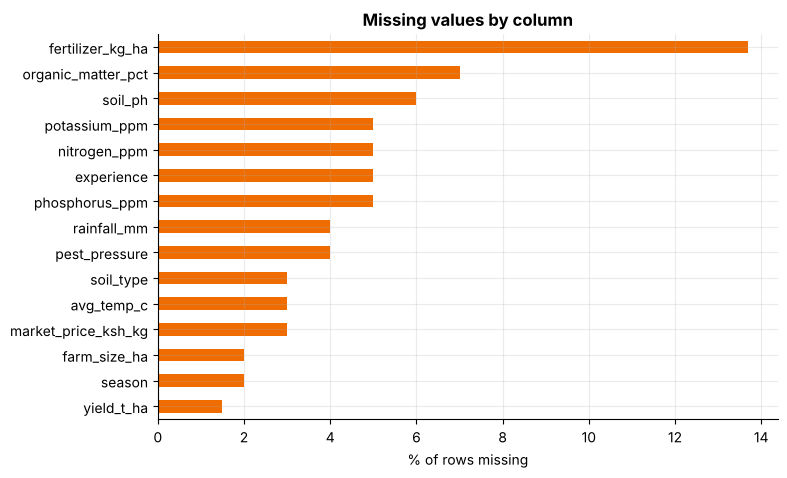

In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
miss[miss > 0].sort_values().plot.barh(ax=ax, color="#EF6C00")
ax.set_xlabel("% of rows missing"); ax.set_title("Missing values by column")
plt.show()

A **missingness map** shows whether gaps are scattered randomly or clustered (each dark mark = one missing cell; rows are farms, sorted by farm size to reveal patterns):

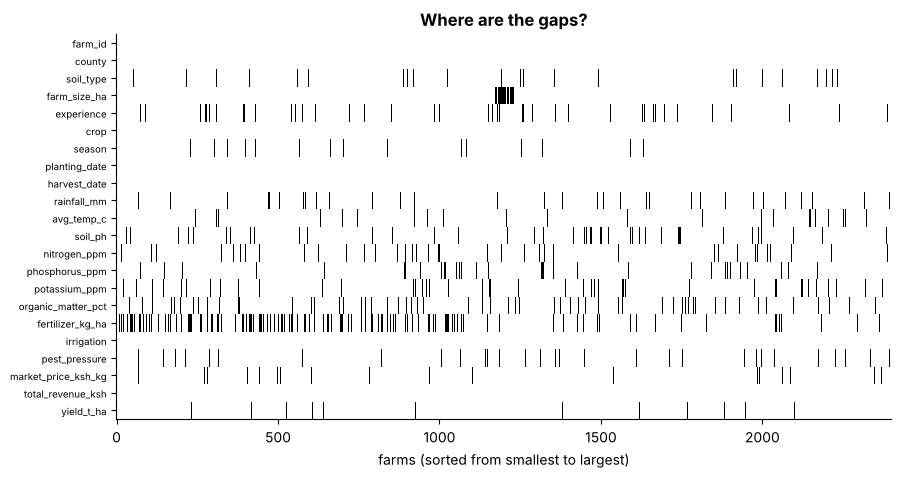

In [19]:
order = df["farm_size_ha"].fillna(df["farm_size_ha"].median()).sort_values().index
m = df.loc[order].isna().to_numpy().T
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(m, aspect="auto", interpolation="none", cmap="Greys")
ax.set_yticks(range(df.shape[1])); ax.set_yticklabels(df.columns, fontsize=7)
ax.set_xlabel("farms (sorted from smallest to largest)"); ax.grid(False)
ax.set_title("Where are the gaps?")
plt.show()

Look at `fertilizer_kg_ha`: the marks bunch to the **left** (small farms). That's visual evidence of **MAR**. Let's confirm with numbers:

In [20]:
small = df["farm_size_ha"] < 1
pd.DataFrame({
    "farms":              [(small).sum(), (~small).sum()],
    "% fertilizer missing": [df.loc[small, "fertilizer_kg_ha"].isna().mean() * 100,
                             df.loc[~small, "fertilizer_kg_ha"].isna().mean() * 100],
}, index=["< 1 ha", ">= 1 ha"]).round(1)

,farms,% fertilizer missing
< 1 ha,1121,23.8
>= 1 ha,1279,4.8


Small farms miss fertilizer several times more often. The gap depends on an *observed* variable (farm size) → **MAR**. A single global average would erase this signal. Good to know *before* we choose a strategy.

## 3.3 Decide: a decision framework

```
                        Is the TARGET (yield) missing?
                           ├── YES → drop the row (can't learn from an unknown answer)
                           └── NO  → is the COLUMN mostly empty (> 40-50%)?
                                        ├── YES → consider dropping the column (or keep as "is_present" flag)
                                        └── NO  → is it numeric or categorical?
                                                     ├── numeric, symmetric       → mean
                                                     ├── numeric, skewed/outliers → median
                                                     ├── numeric, related to a group → group-wise median / KNN / model-based
                                                     ├── categorical              → mode, or a new category "Unknown"
                                                     └── time series              → forward fill / interpolation (past only!)
                        + If missingness is informative (MAR/MNAR): ADD A MISSING-INDICATOR COLUMN
```

## 3.4 Treat: one technique at a time
> ⚠️ **Reminder:** below we compute means and medians from the *whole* dataset to learn the mechanics. In a real project, those numbers must come from the **training set only**: you'll do it properly in Lessons 6–7.

### (a) Drop rows with a missing *target*
We cannot teach a model from a question without an answer.

In [21]:
print("Rows with missing yield:", df["yield_t_ha"].isna().sum())
df = df.dropna(subset=["yield_t_ha"])
print("Rows left:", len(df))

Rows with missing yield: 36
Rows left: 2364


### (b) Drop *columns* that are mostly empty
A simple rule: drop any column with more than X% missing.

In [22]:
threshold = 40
too_empty = miss[miss > threshold].index.tolist()
print(f"Columns with more than {threshold}% missing:", too_empty or "none; nothing to drop here")

Columns with more than 40% missing: none: nothing to drop here


### (c) Mean vs median fill: and the *spike* problem
Farm size is right-skewed (a few huge farms). The mean gets dragged toward the giants.

mean = 2.93 ha   median = 1.07 ha


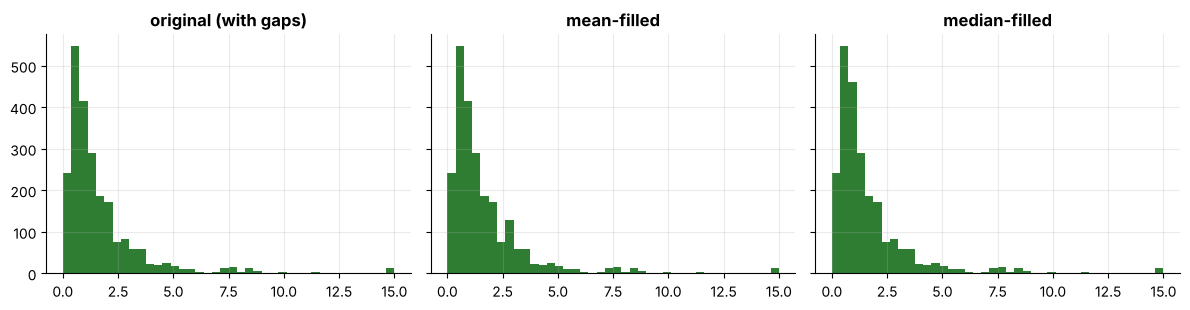

std original: 18.41 | mean-filled: 18.23 | median-filled: 18.23


In [23]:
s = df["farm_size_ha"]
print(f"mean = {s.mean():.2f} ha   median = {s.median():.2f} ha")

mean_fill   = s.fillna(s.mean())
median_fill = s.fillna(s.median())

fig, ax = plt.subplots(1, 3, figsize=(12, 3.2), sharey=True)
for a, series, title in zip(ax, [s, mean_fill, median_fill], ["original (with gaps)", "mean-filled", "median-filled"]):
    a.hist(series.clip(upper=15), bins=40); a.set_title(title)
plt.tight_layout(); plt.show()
print(f"std original: {s.std():.2f} | mean-filled: {mean_fill.std():.2f} | median-filled: {median_fill.std():.2f}")

The tall spike in the middle histograms is the imputed value repeated for every missing farm. For skewed data prefer the median (it isn't pulled by giants), but the spike remains. Let's measure the side-effect on a column with more gaps: fertilizer (≈14% missing, ignoring the absurd values above 300):

In [24]:
f = df["fertilizer_kg_ha"].where(df["fertilizer_kg_ha"] <= 300)
f_mean = f.fillna(f.mean())
print(f"std      original: {f.std():6.1f}   mean-filled: {f_mean.std():6.1f}    ← variance shrinks")

std      original:   46.2   mean-filled:   42.9    ← variance shrinks


The spread shrinks. The second casualty is **correlation**. A quick simulation makes it visible: `y` is strongly related to `x`; now hide 30% of `x` and mean-fill it.

In [25]:
rng = np.random.default_rng(0)
x = rng.normal(size=1000)
y = x + rng.normal(scale=0.5, size=1000)

x_gaps = pd.Series(x).mask(rng.random(1000) < 0.30)          # 30% of x goes missing
x_mean_filled = x_gaps.fillna(x_gaps.mean())
print(f"corr(x, y) true data      : {np.corrcoef(x, y)[0, 1]:.2f}")
print(f"corr(x, y) after mean-fill: {x_mean_filled.corr(pd.Series(y)):.2f}    ← relationship weakened")

corr(x, y) true data      : 0.89
corr(x, y) after mean-fill: 0.77    ← relationship weakened


Constant fills **shrink variance** and **weaken correlations**: the filled rows carry no information yet look like real data. That's the price of simple imputation, and one reason indicators and smarter fills exist.

### (d) Group-wise fill: use what you know about the row
The rainfall in Nakuru isn't the rainfall in Kisii. Fill each gap using the median of the *same county*. (A quick-and-dirty county clean-up: lowercase + remove non-letters. Lesson 2 will do this properly.)

In [26]:
county_tmp = df["county"].str.lower().str.replace(r"[^a-z]", "", regex=True)
rain = df["rainfall_mm"].where(df["rainfall_mm"] > 0)         # ignore impossible negatives for now

global_median = rain.median()
county_median = rain.groupby(county_tmp).transform("median")

filled_global = rain.fillna(global_median)
filled_county = rain.fillna(county_median)

print("Median rainfall by county (mm):")
print(rain.groupby(county_tmp).median().round(0).sort_values().to_string())

Median rainfall by county (mm):
county
machakos      418.0
nakuru        494.0
meru          609.0
nyeri         640.0
uasingishu    641.0
transnzoia    682.0
kiambu        718.0
bungoma       787.0
kakamega      808.0
kisii         895.0


A single global median (≈ 650 mm) would be wrong for dry Machakos and wet Kisii. The county median respects that structure. In the Problem 1.5 you'll *measure* how much better it is.

### (e) Categorical columns: mode or an explicit 'Unknown'

In [27]:
print(df["pest_pressure"].value_counts(dropna=False))

pest_pressure
Low       881
Medium    764
High      401
NaN        96
LOW        62
low        47
HIGH       27
medium     25
med        23
Med        21
high       17
Name: count, dtype: int64


For `pest_pressure`, imputing the mode (`Low`) would claim *"we know it's low"* when we don't. An honest alternative is a new category `'Unknown'`: then the model can learn whether *not knowing* carries information. (We'll standardise spelling first in Lesson 2.)

### (f) Missing-value indicators
When missingness itself may carry information (MAR/MNAR), keep a flag **before** you fill:

In [28]:
df["fertilizer_missing"] = df["fertilizer_kg_ha"].isna().astype(int)
df["fertilizer_filled"] = df["fertilizer_kg_ha"].fillna(df["fertilizer_kg_ha"].median())
df[["farm_size_ha", "fertilizer_kg_ha", "fertilizer_missing", "fertilizer_filled"]].head(6)

,farm_size_ha,fertilizer_kg_ha,fertilizer_missing,fertilizer_filled
0,1.06,66.0,0,66.0
1,0.77,NaN,1,70.0
2,1.69,69.0,0,69.0
3,0.56,0.0,0,0.0
4,2.21,136.0,0,136.0
5,0.79,0.0,0,0.0


### (g) Time series: forward-fill and interpolate
Prices have gaps on days the market wasn't reported. Never fill a price with a *future* value (that's cheating; you wouldn't know it yet). Forward-fill uses the past only.

In [29]:
prices = load_prices()
maize = prices[prices["crop"] == "Maize"].set_index("date")["price_ksh_kg"]
gaps = maize[maize.isna()].index[:3]
print("A few missing days:", [d.date() for d in gaps])

demo = pd.DataFrame({"raw": maize, "ffill": maize.ffill(), "interp": maize.interpolate()}).loc[gaps[0] - pd.Timedelta(days=2): gaps[0] + pd.Timedelta(days=2)]
demo

A few missing days: [datetime.date(2019, 1, 30), datetime.date(2019, 2, 19), datetime.date(2019, 3, 4)]


,raw,ffill,interp
date,,,
2019-01-28,37.88,37.88,37.88
2019-01-29,38.29,38.29,38.29
2019-01-30,NaN,38.29,38.31
2019-01-31,38.33,38.33,38.33
2019-02-01,37.84,37.84,37.84


`ffill` carries yesterday's price forward (safe for forecasting). `interpolate()` draws a line between yesterday and tomorrow: *smoother, but it peeks into the future*, so use it only for analysis, not when building features to predict tomorrow.

### (h) A preview of scikit-learn imputers
Same ideas, but with the `fit` / `transform` split that makes them leak-safe (the core of Lessons 6 and 7):

In [30]:
from sklearn.impute import SimpleImputer, KNNImputer

cols = ["soil_ph", "nitrogen_ppm", "organic_matter_pct"]
X = df[cols].where(df[cols].apply(lambda c: c.between(0, 14) if c.name == "soil_ph" else c > 0))   # ignore impossible values for the demo

imp = SimpleImputer(strategy="median").fit(X)       # LEARN medians
print("learned medians:", dict(zip(cols, imp.statistics_.round(2))))
X_filled = pd.DataFrame(imp.transform(X), columns=cols, index=X.index)   # APPLY them
print("missing after:", int(X_filled.isna().sum().sum()))

knn = KNNImputer(n_neighbors=5).fit(X)              # fill using the 5 most similar rows
X_knn = pd.DataFrame(knn.transform(X), columns=cols, index=X.index)
print("KNN-imputed first rows:\n", X_knn.head(3).round(2))

learned medians: {'soil_ph': np.float64(6.03), 'nitrogen_ppm': np.float64(29.9), 'organic_matter_pct': np.float64(3.2)}
missing after: 0
KNN-imputed first rows:
    soil_ph  nitrogen_ppm  organic_matter_pct
0     6.61          27.6                1.90
1     5.83          17.4                2.68
2     5.58          18.6                2.55


`fit()` = *learn* (medians, neighbours) · `transform()` = *apply*. Remember those two verbs. They are the heart of the entire next two weeks.

---
## 🏁 Where we stand
`df` now has proper numeric/date types, no duplicates, and no rows with a missing target. The categories are still messy (`'Corn'`, `'MAIZE'`…), impossible values (pH = 99) are still there, and extreme outliers remain. **Lesson 2** fixes all of that and saves our structurally-clean dataset.

---
## 🧩 Practice problems
Now it is your turn. Each problem is **self-contained** (it tells you what data to load), so you can do them in any order.

**How to work like a pro:**
1. Read the problem twice. Predict the answer *before* you code.
2. Struggle for at least 10 minutes. Struggling is where learning happens.
3. Open a **hint** only when stuck - they get progressively stronger.
4. Compare with `solutions/solutions_01.ipynb` **after** you have your own answer.

Difficulty: ⭐ warm-up · ⭐⭐ core skill · ⭐⭐⭐ challenge

### Problem 1.1 &nbsp; ⭐ &nbsp; Rescue the fertilizer column

Load the raw farm data. The column `fertilizer_kg_ha` contains values like `'85'`, `'85 kg'`, `'85kg/ha'`, `'unknown'` and `'-'`. (There were also `'N/A'` strings in the file, but `read_csv` already turned those into NaN when loading; a good reminder that `read_csv` silently treats some strings as missing.)

1. List the **distinct strings that contain no digits** at all.
2. Convert the column to a proper numeric column (`float`).
3. Report how many values are missing **before** and **after** conversion. Should they differ? Why?

<details><summary>💡 Hint 1</summary>

`s.str.contains(r'\d')` is True when a string has a digit. Use `~` to negate and `.dropna()` first.

</details>

<details><summary>💡💡 Hint 2</summary>

`s.str.extract(r'(\d+\.?\d*)', expand=False)` pulls out the number; wrap in `pd.to_numeric`.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Before: only truly empty cells are NaN. After: the text placeholders `N/A`, `unknown`, `-` become NaN too, so the count rises by exactly the number of placeholder strings.

</details>

In [31]:
# ✏️ Your code here

### Problem 1.2 &nbsp; ⭐⭐ &nbsp; Dates and impossible timelines

Convert `planting_date` and `harvest_date` to real datetimes. Then:

1. How many rows have a **harvest date earlier than the planting date**?
2. What is the minimum and maximum planting date?
3. Show 3 of the offending rows.

<details><summary>💡 Hint 1</summary>

`pd.to_datetime(col, format='mixed')` handles several text formats in one column.

</details>

<details><summary>💡💡 Hint 2</summary>

A boolean mask: `harvest < plant`. `mask.sum()` counts them.

</details>

<details><summary>💡💡💡 Hint 3</summary>

Use `raw.loc[mask, ['farm_id','planting_date','harvest_date']].head(3)`.

</details>

In [32]:
# ✏️ Your code here

### Problem 1.3 &nbsp; ⭐⭐ &nbsp; Hunt the hidden duplicates

1. How many rows are *exact* duplicates of an earlier row (`df.duplicated()`)?
2. Now convert the dates (see Problem 1.2) and count rows that repeat the **natural key** `farm_id + planting_date`.
3. Why is the second number larger? Show one pair of "near duplicates" side by side.

<details><summary>💡 Hint 1</summary>

Exact: `raw.duplicated().sum()`.

</details>

<details><summary>💡💡 Hint 2</summary>

Natural key: `raw.duplicated(subset=['farm_id','planting_date']).sum()`: but only after dates have the same type/format!

</details>

<details><summary>💡💡💡 Hint 3</summary>

To see a pair: `k = raw[raw.duplicated(subset=key, keep=False)].sort_values(key)`; `k.head(2).T` is easiest to read.

</details>

In [33]:
# ✏️ Your code here

### Problem 1.4 &nbsp; ⭐⭐ &nbsp; Is the missingness random?

Convert fertilizer to numeric (as in Problem 1.1). Compare the **percentage of missing fertilizer values** between small farms (`farm_size_ha < 1`) and larger farms (`>= 1`).

Is this missing data MCAR, MAR or MNAR? What does it imply for how we should fill it?

<details><summary>💡 Hint 1</summary>

Create `is_small = raw['farm_size_ha'] < 1` and a Series `raw['fertilizer_kg_ha'].isna()`.

</details>

<details><summary>💡💡 Hint 2</summary>

`raw.groupby(is_small)['fertilizer_kg_ha'].apply(lambda s: s.isna().mean() * 100)`

</details>

<details><summary>💡💡💡 Hint 3</summary>

If the rate differs a lot between groups, missingness depends on an *observed* column (farm size) → MAR.

</details>

In [34]:
# ✏️ Your code here

### Problem 1.5 &nbsp; ⭐⭐⭐ &nbsp; Which imputation strategy is best? Run an experiment!

We can *test* imputation by hiding values we actually know.

Using `rainfall_mm` (keep only rows where it is present and > 0):
1. Clean the county text with `s.str.lower().str.replace(r'[^a-z]', '', regex=True)`.
2. Randomly hide 15% of the values (use `np.random.default_rng(0)`).
3. Fill them three ways: **global mean**, **global median**, **county median** (learned from the *visible* values only).
4. Compute the RMSE of each strategy against the truth. Which wins, and why?

<details><summary>💡 Hint 1</summary>

`mask = rng.random(len(d)) < 0.15` marks the values to hide. Keep `truth = d['rainfall_mm'][mask]`.

</details>

<details><summary>💡💡 Hint 2</summary>

`visible = d['rainfall_mm'].where(~mask)` is the series with hidden values set to NaN.

</details>

<details><summary>💡💡💡 Hint 3</summary>

County median learned from visible values: `visible.groupby(d['county']).transform('median')`. RMSE = `np.sqrt(((pred - truth) ** 2).mean())`.

</details>

In [35]:
# ✏️ Your code here

---
## ✅ Check your understanding
Answer in your head first, *then* click to reveal.

**Q1.** A column of fertilizer amounts is stored as text like '85 kg'. What is the best first step?

- **A)** Drop the column
- **B)** Extract the numeric part and convert to float, then inspect what failed to convert
- **C)** Fill with zeros
- **D)** Leave it: models can read text

<details><summary>Show answer</summary>

**B**: Convert deliberately and *inspect the failures*. Blindly using `errors='coerce'` hides problems.

</details>

**Q2.** Rows A and B are identical except 'Maize' vs 'MAIZE'. `df.duplicated()` will…

- **A)** Flag B as a duplicate
- **B)** Not flag them: strings differ
- **C)** Raise an error
- **D)** Flag both

<details><summary>Show answer</summary>

**B**: Exact matching is case-sensitive. Standardise text and/or use a natural key before de-duplicating.

</details>

**Q3.** Farmers with very *poor* yields refuse to report their yields. This missingness is…

- **A)** MCAR
- **B)** MAR
- **C)** MNAR
- **D)** Not a problem

<details><summary>Show answer</summary>

**C**: Missingness depends on the unobserved value itself → MNAR. It cannot be repaired by imputation from other columns alone; at best flag it and be cautious.

</details>

**Q4.** Why does filling every NaN with the mean *shrink* the variance of a column?

- **A)** It doesn't
- **B)** Because many points now sit exactly at the mean, adding zero spread
- **C)** Because the mean is biased
- **D)** Because NaN has negative variance

<details><summary>Show answer</summary>

**B**: Imputed values add no new information and pile up at the centre, making the distribution artificially narrow and weakening correlations.

</details>

---
## 📌 Summary: what to remember
- Convert types deliberately: regex-extract numbers, `to_datetime(format='mixed')`, then *inspect what failed*.
- Use a **natural key** (`farm_id + planting_date`) to find near-duplicates; convert & standardise first, dedupe second.
- Diagnose missingness (MCAR/MAR/MNAR) *before* choosing a strategy.
- Drop rows with missing target; fill features with median/group median/'Unknown'; add indicators when missingness is informative.
- Anything that *learns a number* belongs in a `fit`/`transform` pipeline fitted on training data only.

## 🚧 Common mistakes
- ⚠️ `errors='coerce'` silently destroys rescuable data.
- ⚠️ Mean-filling a skewed column and shrinking its variance.
- ⚠️ Interpolating or back-filling time series: it leaks the future.
- ⚠️ Dropping all rows with any NaN (you may lose most of your data).

➡️ **Next:** Lesson 02: Inconsistent records, invalid values and outliers.